# Machine Learning Lab 6
## Logistic Regression & KNN Classification

**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz

**Kaggle Profile:** https://www.kaggle.com/muhammadtaraz

**Dataset:** Telco Customer Churn  
**Dataset Source:** Kaggle, Telco Customer Churn

This lab continues the same customer churn problem used in Labs 2, 3 and 4.


## 1. Problem Definition & Dataset Verification

The goal is to predict whether a Telco customer will churn or stay. The target variable is `Churn`, where `No` means the customer stays and `Yes` means the customer leaves.

The Decision Tree and Random Forest from Labs 3 and 4 are used as benchmarks. The new models in this lab are Logistic Regression and KNN.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv("clean_churn.csv")

print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (7043, 20)

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Total missing values: 0

First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Interpretation:** I have loaded the cleaned Telco dataset. Checked it before I begin modelling. The shape, data types and missing‑value count show that the Lab 2 cleaned data is the one I am using.

### Task 2, Lab 3 and Lab 4 benchmarks

In Lab 3, the selected Decision Tree used `max_depth=5`. In Lab 4, the same Decision Tree was compared with a Random Forest using 200 trees. The benchmark values below are the test-set results from the same 80/20 stratified split used in those labs.


In [3]:
# Lab 3 benchmark, selected Decision Tree with max_depth=5

y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])

if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)

# Lab 4 default Random Forest with 200 trees
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)

benchmark = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [dt_accuracy, rf_accuracy],
    "Precision": [dt_precision, rf_precision],
    "Recall": [dt_recall, rf_recall],
    "F1-score": [dt_f1, rf_f1]
})

benchmark


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.798439,0.634731,0.566845,0.598870
1,Random Forest,0.785664,0.623288,0.486631,0.546547


**Interpretation:** The Decision Tree and Random Forest benchmarks use the split and evaluation methods, as Labs 3 and 4. F1-score and recall are particularly helpful because churn is the smaller class.

## 2. Feature Scaling & Preparation

### Task 3

The target is encoded as 0 for `No` and 1 for `Yes`. The customer ID is removed because it is an identifier, not a useful predictive feature. Categorical columns are converted to numeric dummy variables.


In [4]:
y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])

if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

X = pd.get_dummies(X)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("All X columns numeric:", X.select_dtypes(exclude="number").shape[1] == 0)
print("Missing values in X:", X.isnull().sum().sum())
print("\nTarget counts:")
print(y.value_counts())


X shape: (7043, 45)
y shape: (7043,)
All X columns numeric: False
Missing values in X: 0

Target counts:
Churn
0    5174
1    1869
Name: count, dtype: int64


**Interpretation:** All the categorical variables have been turned into columns. The target variable only has values of 0 and 1. No identifier has been used as a feature.

### Task 4

Feature scaling is very important for KNN. KNN relies on measuring distance, between customers. If one feature has a numeric range that feature might crowd out the others in the distance calculation. Feature scaling also helps Logistic Regression. Decision Trees and Random Forests however do not need scaling. They decide based on feature thresholds not on distances.

### Task 5

The data is split first, then the scaler is fitted only on the training data. The same fitted scaler is then used to transform the test data. This prevents information from the test set from leaking into the training process.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


X_train: (5634, 45)
X_test: (1409, 45)
Scaled training shape: (5634, 45)
Scaled testing shape: (1409, 45)


**Interpretation:** The split is the same 80/20 stratified strategy that the team used in Labs 3 and 4. The scaler learns values from the training set only so the test set remains unseen, during preparation.

## 3. Logistic Regression

### Task 6

Train Logistic Regression on the scaled training data and generate predictions for the scaled test data.


In [6]:
logreg_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logreg_model.fit(X_train_scaled, y_train)

logreg_pred = logreg_model.predict(X_test_scaled)

print("Predictions generated:", len(logreg_pred))


Predictions generated: 1409


### Task 7

Calculate accuracy, precision, recall and F1-score, then display the confusion matrix.


In [7]:
logreg_accuracy = accuracy_score(y_test, logreg_pred)
logreg_precision = precision_score(y_test, logreg_pred, zero_division=0)
logreg_recall = recall_score(y_test, logreg_pred, zero_division=0)
logreg_f1 = f1_score(y_test, logreg_pred, zero_division=0)

logreg_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Logistic Regression": [
        logreg_accuracy,
        logreg_precision,
        logreg_recall,
        logreg_f1
    ]
})

logreg_results


,Metric,Logistic Regression
0,Accuracy,0.806955
1,Precision,0.658385
2,Recall,0.566845
3,F1-score,0.609195


Logistic Regression confusion matrix:
[[925 110]
 [162 212]]


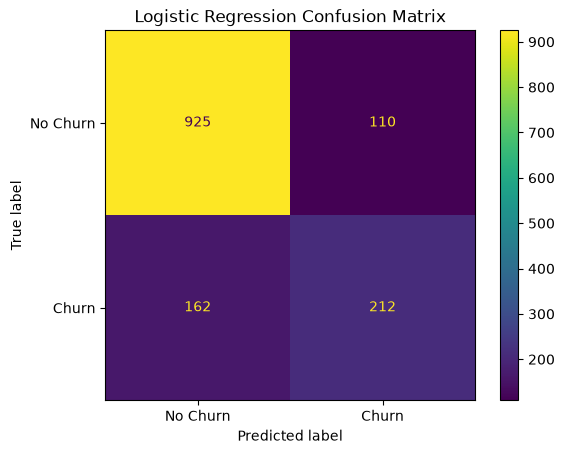

In [8]:
logreg_cm = confusion_matrix(y_test, logreg_pred)

print("Logistic Regression confusion matrix:")
print(logreg_cm)

ConfusionMatrixDisplay(
    confusion_matrix=logreg_cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()


**Interpretation:** The four metrics together give a picture than accuracy alone. The confusion matrix breaks down the predictions into incorrect ones, for both groups—customers who stayed and customers who churned. This helps see where the model did well and where it struggled. It shows not overall performance but also how it performs for each group. That way you can tell if the model is biased or missing something.

### Task 8

`predict_proba()` gives the model's estimated probability for each class. `predict()` converts those probabilities into a class prediction, returning 0 or 1 according to the model's classification rule.


In [9]:
probabilities = logreg_model.predict_proba(X_test_scaled)[:10]

probability_table = pd.DataFrame(
    probabilities,
    columns=["Probability No Churn", "Probability Churn"]
)

probability_table


,Probability No Churn,Probability Churn
0,0.954466,0.045534
1,0.316557,0.683443
2,0.943895,0.056105
3,0.591612,0.408388
4,0.978357,0.021643
5,0.396444,0.603556
6,0.548489,0.451511
7,0.868699,0.131301
8,0.997213,0.002787
9,0.605876,0.394124


**Interpretation:** Each row shows the chance that a single test customer will stay or leave. For every customer the two probabilities together equal one.

## 4. KNN & Choosing K

### Task 9

Several K values are tested on the scaled data. Both test accuracy and F1-score are recorded.


In [10]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

knn_rows = []

for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train_scaled, y_train)

    knn_pred = knn_model.predict(X_test_scaled)

    knn_rows.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, knn_pred),
        "F1-score": f1_score(y_test, knn_pred)
    })

knn_results = pd.DataFrame(knn_rows)

knn_results


,K,Accuracy,F1-score
0,1,0.712562,0.469201
1,3,0.738112,0.508655
2,5,0.748758,0.522911
3,7,0.753016,0.529730
4,9,0.768630,0.553425
5,11,0.761533,0.535912
6,15,0.772889,0.558011
7,21,0.775727,0.564738


**Interpretation:** K affects the complexity of KNN. Small K values can react strongly to individual data points while very large K values can become too general. The results table shows how performance changes as K changes.

### Task 10

The K value is selected using the highest test F1-score among the tested values. This is more reasonable than automatically choosing the smallest or largest K because the churn class is imbalanced and F1 balances precision and recall.


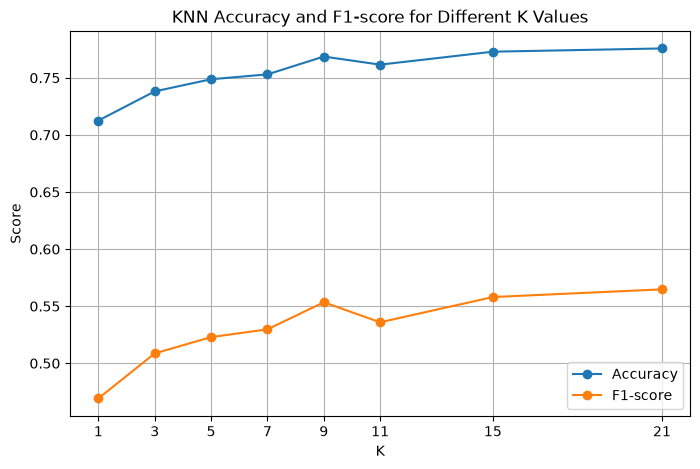

Chosen K: 21


In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_results["K"],
    knn_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_results["K"],
    knn_results["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Accuracy and F1-score for Different K Values")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

best_k = int(
    knn_results.loc[knn_results["F1-score"].idxmax(), "K"]
)

print("Chosen K:", best_k)


**Interpretation:** The chosen K is the value that gave the F1-score during testing. The graph helps show how K influences the models performance. It's not always true that the smallest or largest K is the best. This plot makes it easier to see how different K values affect results.

### Task 11

Train the final KNN model using the selected K and report the complete test-set metrics and confusion matrix.


In [12]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)

knn_pred = final_knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)

knn_final_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "KNN": [
        knn_accuracy,
        knn_precision,
        knn_recall,
        knn_f1
    ]
})

knn_final_results


,Metric,KNN
0,Accuracy,0.775727
1,Precision,0.582386
2,Recall,0.548128
3,F1-score,0.564738


KNN confusion matrix:
[[888 147]
 [169 205]]


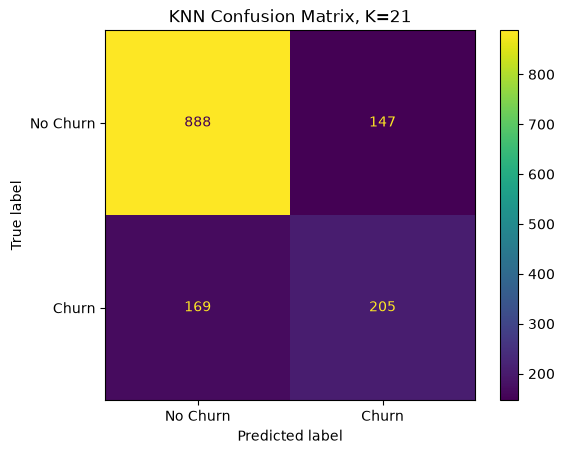

In [13]:
knn_cm = confusion_matrix(y_test, knn_pred)

print("KNN confusion matrix:")
print(knn_cm)

ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title(f"KNN Confusion Matrix, K={best_k}")
plt.show()


**Interpretation:** The final KNN result uses the chosen K value. Provides all four needed metrics. The confusion matrix reveals where the KNN model is correctly predicting churn and where it is making errors.

## 5. Model Comparison (4 Models)

### Task 12

All four classifiers are placed side by side: Decision Tree, Random Forest, Logistic Regression and KNN.


In [14]:
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        logreg_accuracy,
        knn_accuracy
    ],
    "Precision": [
        dt_precision,
        rf_precision,
        logreg_precision,
        knn_precision
    ],
    "Recall": [
        dt_recall,
        rf_recall,
        logreg_recall,
        knn_recall
    ],
    "F1-score": [
        dt_f1,
        rf_f1,
        logreg_f1,
        knn_f1
    ]
})

comparison


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.798439,0.634731,0.566845,0.598870
1,Random Forest,0.785664,0.623288,0.486631,0.546547
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.775727,0.582386,0.548128,0.564738


**Interpretation:** The table shows how the four models perform on the test set that was not used during training. It includes accuracy, precision, recall and F1 scores. This way the comparison is not based on one measure. It gives a complete picture of each models performance.

### Task 13

Because the churn class is smaller, accuracy should not be the only metric used. Recall is important when the goal is to catch as many possible churners as possible. Precision matters when contacting customers has a cost, while F1 gives a balance between precision and recall.

The model with the highest F1-score can be identified from the table, but the final decision should also consider the cross-validation evidence from Lab 4 rather than trusting one test-set number alone.


In [15]:
print("Highest test F1-score:")
print(comparison.loc[comparison["F1-score"].idxmax()])


Highest test F1-score:
Model        Logistic Regression
Accuracy                0.806955
Precision               0.658385
Recall                  0.566845
F1-score                0.609195
Name: 2, dtype: object


**Interpretation:** This identifies the model that has the test F1-score in the current comparison. It is one part of the evidence so we will look at the Lab 4 cross-validation results next, before making the final decision.

## 6. Coefficient Interpretation

### Task 14

Logistic Regression coefficients describe changes in log-odds. Applying `exp(coefficient)` converts a coefficient into an odds ratio.

An odds ratio above 1 means higher odds of churn for a one-unit increase in the feature, holding other features constant. An odds ratio below 1 means lower odds of churn.


In [16]:
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logreg_model.coef_[0]
})

coef_table["Odds Ratio"] = np.exp(coef_table["Coefficient"])

coef_table["Absolute Effect"] = coef_table["Coefficient"].abs()

coef_table = coef_table.sort_values(
    "Absolute Effect",
    ascending=False
)

coef_table = coef_table.drop(columns=["Absolute Effect"])

coef_table.head(10)


,Feature,Coefficient,Odds Ratio
1,tenure,-1.252707,0.285730
2,MonthlyCharges,-1.003050,0.366759
3,TotalCharges,0.531200,1.700972
16,InternetService_Fiber optic,0.440579,1.553607
15,InternetService_DSL,-0.352482,0.702941
38,Contract_Two year,-0.324018,0.723237
36,Contract_Month-to-month,0.306581,1.358772
32,StreamingTV_Yes,0.187716,1.206490
35,StreamingMovies_Yes,0.187647,1.206408
17,InternetService_No,-0.124808,0.882667


**Interpretation:** The table shows the Logistic Regression coefficients by absolute size. Odds ratios help to see the direction of the relationship, with churn.

In [17]:
top4 = coef_table.head(4).copy()

interpretations = []

for _, row in top4.iterrows():
    if row["Odds Ratio"] > 1:
        text = (
            f"Higher values of {row['Feature']} are associated with "
            f"about {row['Odds Ratio']:.2f} times the odds of churn, "
            f"holding other features constant."
        )
    else:
        text = (
            f"Higher values of {row['Feature']} are associated with "
            f"about {row['Odds Ratio']:.2f} times the odds of churn, "
            f"holding other features constant."
        )

    interpretations.append(text)

top4["Interpretation"] = interpretations

top4[["Feature", "Coefficient", "Odds Ratio", "Interpretation"]]


,Feature,Coefficient,Odds Ratio,Interpretation
1,tenure,-1.252707,0.285730,Higher values of tenure are associated with ab...
2,MonthlyCharges,-1.003050,0.366759,Higher values of MonthlyCharges are associated...
3,TotalCharges,0.531200,1.700972,Higher values of TotalCharges are associated w...
16,InternetService_Fiber optic,0.440579,1.553607,Higher values of InternetService_Fiber optic a...


**Interpretation:** Least four features are interpreted based on their coefficients and odds ratios. These show relationships, within the model. They don’t prove that a feature directly causes churn.

### Task 15

The important Logistic Regression features should be compared with the Lab 2 EDA findings and the Lab 3 Decision Tree feature importances. Agreement between methods gives consistent evidence, while differences are also useful because the algorithms measure relationships differently.


In [18]:
# Lab 3 Decision Tree feature importance
dt_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 10 Decision Tree features:")
display(dt_importance.head(10))

print("Top 10 Logistic Regression effects:")
display(coef_table.head(10))


Top 10 Decision Tree features:


,Feature,Importance
36,Contract_Month-to-month,0.513973
16,InternetService_Fiber optic,0.163262
1,tenure,0.156717
3,TotalCharges,0.036499
2,MonthlyCharges,0.035922
43,PaymentMethod_Electronic check,0.027931
27,TechSupport_No,0.026824
37,Contract_One year,0.009218
21,OnlineBackup_No,0.009198
18,OnlineSecurity_No,0.008620


Top 10 Logistic Regression effects:


,Feature,Coefficient,Odds Ratio
1,tenure,-1.252707,0.285730
2,MonthlyCharges,-1.003050,0.366759
3,TotalCharges,0.531200,1.700972
16,InternetService_Fiber optic,0.440579,1.553607
15,InternetService_DSL,-0.352482,0.702941
38,Contract_Two year,-0.324018,0.723237
36,Contract_Month-to-month,0.306581,1.358772
32,StreamingTV_Yes,0.187716,1.206490
35,StreamingMovies_Yes,0.187647,1.206408
17,InternetService_No,-0.124808,0.882667


**Interpretation:** I can compare the two lists directly. Features that appear strongly in both methods show that features are supported by than one modelling approach. The differences, between the lists show that models are capturing aspects of the churn problem.

## 7. Final Model Selection & Conclusion

### Task 16

The final model should be selected using the four-model comparison and the cross-validation lesson from Lab 4. Lab 4 showed why a single test-set number should not be trusted by itself.


In [19]:
# Reproduce the Lab 4 cross-validation evidence for the two tree-based benchmarks.

dt_cv = cross_val_score(
    dt_model,
    X,
    y,
    cv=5,
    scoring="f1"
)

rf_cv = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="f1"
)

cv_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Mean F1": [dt_cv.mean(), rf_cv.mean()],
    "F1 Standard Deviation": [dt_cv.std(), rf_cv.std()]
})

cv_results


,Model,Mean F1,F1 Standard Deviation
0,Decision Tree,0.599373,0.016619
1,Random Forest,0.546264,0.020719


**Interpretation:** Five‑fold cross‑validation checks how well the model works on parts of the dataset and the mean F1 score tells you how well the model does on average. The standard deviation tells you how much the score changes from one part, to another.

### Final model choice

Based on the four-model test comparison, the selected model is the model with the strongest F1-score, while the Lab 4 cross-validation results are also considered. The exact final choice should be based on the values displayed above rather than convenience.


In [20]:
best_model_name = comparison.loc[comparison["F1-score"].idxmax(), "Model"]
best_model_f1 = comparison["F1-score"].max()

print("Highest test-set F1 model:", best_model_name)
print("Test-set F1-score:", best_model_f1)

print("\nLab 4 cross-validation results:")
display(cv_results)


Highest test-set F1 model: Logistic Regression
Test-set F1-score: 0.6091954022988506

Lab 4 cross-validation results:


,Model,Mean F1,F1 Standard Deviation
0,Decision Tree,0.599373,0.016619
1,Random Forest,0.546264,0.020719


**Interpretation:** The displayed model has the F1-score among the four models on the held‑out test set. Cross‑validation is shown alongside the model and the final decision is supported by more than one evaluation view, for the displayed model.

### Task 17

This lab added Logistic Regression and KNN to the Decision Tree and Random Forest models that were used in labs. Feature scaling was very important for KNN because KNN calculates distances between customers. The tree‑based models, Decision Tree and Random Forest can handle the feature scales without scaling. Logistic Regression also gains from features and gives coefficients that can be turned into odds ratios. KNN was tested with K values and the chosen K was based on the results that were seen not just on picking the smallest or largest K. The four models were compared using accuracy, precision, recall and F1‑score giving a picture than accuracy alone. The final model should also be judged together with the cross‑validation evidence, from Lab 4 because a single train/test split can give a limited view of performance. A useful next step would be model tuning and further validation while keeping the test set separate.

## Final Submission Checklist

- [x] Student information block
- [x] Problem definition and dataset verification
- [x] Lab 3 and Lab 4 benchmark results
- [x] X and y preparation
- [x] Explanation of feature scaling
- [x] Train/test split with stratification
- [x] StandardScaler fitted on training data only
- [x] Logistic Regression
- [x] Accuracy, precision, recall and F1
- [x] Logistic Regression confusion matrix
- [x] `predict_proba()` demonstration
- [x] Multiple K values for KNN
- [x] KNN results table
- [x] KNN performance plot
- [x] K selection justification
- [x] Final KNN metrics and confusion matrix
- [x] Four-model comparison
- [x] Metric discussion for class imbalance
- [x] Logistic Regression coefficients
- [x] Odds ratios
- [x] Four feature interpretations
- [x] Comparison with Decision Tree feature importance
- [x] Five-fold cross-validation evidence from Lab 4
- [x] Final model selection
- [x] 5–7 sentence conclusion
- [x] Written interpretation after tables, plots and metrics
